# 06 · Travel time: how old is the water reaching the well?

Tutorial 01 mapped *where* the water pumped by the supply well comes from. Protection zones also ask *how long* it takes to get there: a pollutant spilled 50 days upgradient of a well behaves very differently from one spilled 50 years upgradient. This tutorial adds travel time to the same backward trace.

You will:

1. give the trace a **porosity** and see how it turns flows into water volumes and residence times;
2. compute the **Eulerian mean travel time** to the well for every cell, conditional on the water reaching the well;
3. draw **time-of-travel zones** (50 days, 400 days, 5 and 25 years) and see what this grid can and cannot resolve;
4. check the exact **volume identity**: the flux-weighted mean travel time equals the volume of water that will end at the well divided by the pumping rate;
5. track flux-weighted particles with **MODFLOW 6 PRT** through the package's helper and compare: overall means, then cell by cell;
6. understand why full mixing and advection agree on average but differ cell by cell, and which to use for which job.

**Runtime:** about 20 seconds (the particle run takes about 10 s). **Prerequisites:** tutorial 01.

## Settings

All settings live in this first cell. **Porosity has no default anywhere in `gwsource`**: a steady flow model does not use it, so the travel time must be told. The model workspace and the particle run go to `tutorials/_work/06_travel_time/` (git-ignored, recreated on every run). Shared builders and plots are in [`herebedragons.py`](../herebedragons.py); three small functions specific to this tutorial (flux-weighted means and zone areas) are in [`helpers.py`](helpers.py) next to this notebook.

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
sys.path.insert(0, str(Path.cwd()))  # this folder holds helpers.py
import helpers  # noqa: E402
import herebedragons as hbd  # noqa: E402

import gwsource as gs  # noqa: E402
from gwsource import PrtConfig, track_particles  # noqa: E402
from gwsource.traveltime import exit_cell_closure, travel_time_closure  # noqa: E402

WORK = hbd.work_dir("06_travel_time", clean=True)  # tutorials/_work/06_travel_time (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = "supply_well"  # boundname of the well we trace
POROSITY = 0.3  # effective porosity (-), the same for the Eulerian times and the particles
POROSITY_LOW = 0.2  # a second value, to show how times scale with porosity
YEAR = helpers.DAYS_PER_YEAR  # days
ZONE_TIMES = {"50 d": 50.0, "400 d": 400.0, "5 yr": 5 * YEAR, "25 yr": 25 * YEAR}  # days
CAPTURE_F = 0.5  # a cell belongs to the capture zone where F >= CAPTURE_F (tutorial 01)
MAP_F_MIN = 0.1  # maps of travel time hide cells with F below this
PRT_SUBDIVISIONS = 2  # 4 x 2^2 = 16 particles per source term in a DIS cell
SOURCE_LABELS = {"RCH": "recharge", "RIV": "river leakage", "CHD": "west edge (regional inflow)"}

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. The model and the backward trace

This is the quickstart model of tutorial 01: one unconfined layer of 2 km × 2 km in 50 m cells, recharge everywhere, a constant-head west edge, a north–south river and a supply well pumping 800 m³/d next to it. We build it, read its single steady time step, and trace backward from the well exactly as in tutorial 01.

In [2]:
run = hbd.build_quickstart(WORK / "model", MF6)
spec = run.spec
step = gs.read_step(run.ws, boundnames=True)
well = gs.select(step, boundnames=[WELL])
well_cell = int(np.flatnonzero(well.cells)[0])
res = gs.backward(step, {WELL: well})
F = res.fraction_through[WELL]
print(f"{step.n_cells} cells of {spec.delr:.0f} m; solver: {res.solver_used[0]}")
print(f"water reaching the well: {res.destination_inflow[WELL]:.1f} m3/d")
print(f"capture zone (F >= {CAPTURE_F}): {step.area[F >= CAPTURE_F].sum() / 1e6:.3f} km2")

1600 cells of 50 m; solver: topological
water reaching the well: 800.0 m3/d
capture zone (F >= 0.5): 1.143 km2


## 2. Porosity, water volume and residence time

Travel time needs the volume of water in each cell, not only the flows:

$$
V_i = n_i \, A_i \, b_i , \qquad \tau_i = \frac{V_i}{O_i} ,
$$

with $n_i$ the effective porosity, $A_i$ the plan area, $b_i$ the saturated thickness and $O_i$ the total outflow of the cell. The saturated thickness comes from the DATA-SAT record that MF6 writes when NPF has `SAVE_SATURATION` (otherwise from the heads). A fully mixed cell is a well-mixed reservoir: water spends on average $\tau_i$ in it, its **residence time**.

`gs.travel_time(step, res, porosity)` takes the backward result and the porosity (a scalar or one value per cell) and reuses the factorised matrix of the backward solve.

saturated thickness from: DATA-SAT
saturated thickness: 34.3 to 40.0 m
water in the model: 45.6 million m3
residence time in the well cell: 32.2 d


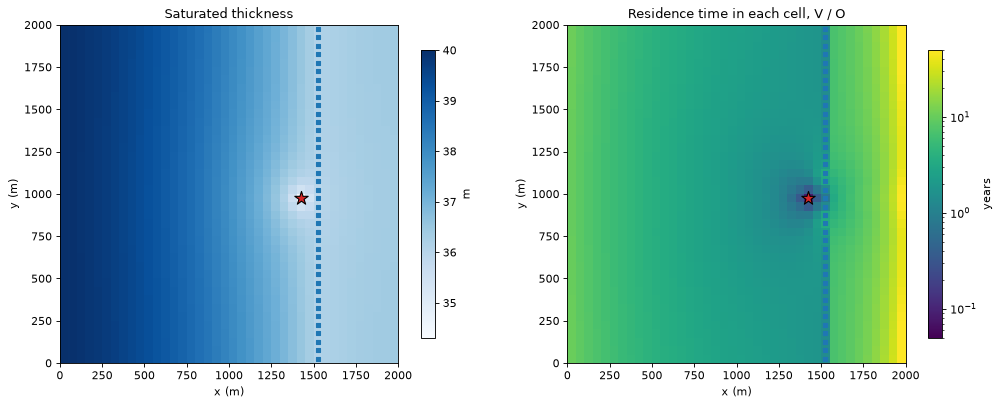

In [3]:
tt = gs.travel_time(step, res, POROSITY)
print("saturated thickness from:", step.notes["thickness_from"])
print(f"saturated thickness: {np.nanmin(step.saturated_thickness):.1f} to {np.nanmax(step.saturated_thickness):.1f} m")
print(f"water in the model: {tt.water_volume.sum() / 1e6:.1f} million m3")
print(f"residence time in the well cell: {tt.residence_time[well_cell]:.1f} d")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))
hbd.plot_cells(
    run.grb_file, step, step.saturated_thickness, ax=axes[0], cmap="Blues",
    title="Saturated thickness", label="m", overlay=False,
)
hbd.plot_cells(
    run.grb_file, step, tt.residence_time / YEAR, ax=axes[1], cmap="viridis",
    norm=LogNorm(0.05, 50.0), title="Residence time in each cell, V / O", label="years", overlay=False,
)
for ax in axes:
    hbd.overlay_features(ax, run.grb_file, step, packages=("RIV", "WEL"), legend=False)
fig.tight_layout()
plt.show()

A 50 m × 50 m cell holds about 28,000 m³ of water, and the flow through it grows from west to east as recharge accumulates along the flow paths, so most cells hold their water for one to a few years. The residence time is longest near the no-flow east edge, where only the local recharge passes through, and shortest where the flow converges on the well: the well cell is flushed in about a month.

### Times scale with porosity

In a steady model the flows do not depend on porosity, so every travel time is exactly proportional to it. A range of plausible porosities is therefore a range of times, with no rerun needed:

In [4]:
tt_low = gs.travel_time(step, res, POROSITY_LOW)
captured = np.isfinite(tt.mean_time[WELL])
ratio = tt_low.mean_time[WELL][captured] / tt.mean_time[WELL][captured]
print(f"mean time with n = {POROSITY_LOW} / mean time with n = {POROSITY}: "
      f"{ratio.min():.6f} to {ratio.max():.6f} (expected {POROSITY_LOW / POROSITY:.6f})")

mean time with n = 0.2 / mean time with n = 0.3: 0.666667 to 0.666667 (expected 0.666667)


In a transient model this is no longer exact (storage changes the flows), and tutorial 08 treats porosity and specific yield separately.

## 3. The Eulerian mean travel time

The fraction through $F_i$ says how much of the water passing through cell $i$ reaches the well. Under the same full-mixing assumption, the expected travel time follows from one more right-hand side on the same matrix (`PLAN.md` [§2.6](../../PLAN.md)):

$$
(\mathbf I - \mathbf P)\,\mathbf m = \boldsymbol\tau \circ \mathbf F ,
\qquad
\bar t_i = \frac{m_i}{F_i} .
$$

$m_i$ is the expected travel time weighted by the chance of reaching the well, and $\bar t_i$ (`tt.mean_time`) is the **mean travel time of the water that does reach the well**, from entering cell $i$ until it leaves the model through the well. It is *conditional*: a cell on the edge of the capture zone with $F = 0.05$ still has a well-defined mean time for its 5 % that reaches the well. That is why the maps below hide cells with small $F$.

Two end points are available:

- `mean_time` stops when the water leaves through the well, so it includes the residence in the well cell itself (about a month here);
- `mean_time_to_exit_cell` stops when the water *enters* the well cell. Particle trackers such as MF6 PRT stop a particle there, so this is the one to compare with particles (section 6).

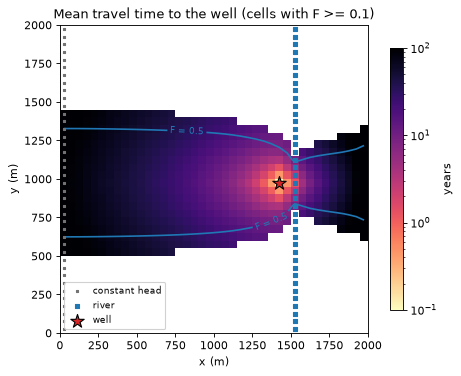

inside the capture zone: median 34 yr, 5-95 % range 3.0 to 104 yr


In [5]:
t_well = tt.mean_time[WELL]
t_map = np.where(F >= MAP_F_MIN, t_well, np.nan)

ax = hbd.plot_cells(
    run.grb_file, step, t_map / YEAR, cmap="magma_r", norm=LogNorm(0.1, 100.0),
    title=f"Mean travel time to the well (cells with F >= {MAP_F_MIN})", label="years",
)
hbd.add_contours(ax, run.grb_file, step, F, (CAPTURE_F,), colors="tab:blue")
plt.show()

inside = F >= CAPTURE_F
print(f"inside the capture zone: median {np.median(t_well[inside]) / YEAR:.0f} yr, "
      f"5-95 % range {np.percentile(t_well[inside], 5) / YEAR:.1f} to "
      f"{np.percentile(t_well[inside], 95) / YEAR:.0f} yr")

Travel times grow with distance from the well along the flow paths, from months next to the well to a century at the western end of the capture zone, where the water has crossed more than a kilometre of aquifer. The tail east of the river is also decades old: that water moves slowly from the quiet east side of the model before it is mixed into the river cells next to the well.

## 4. Time-of-travel zones

A time-of-travel zone is the part of the capture zone from which water reaches the well within a given time. With the outputs above, for a limit $T$:

$$
Z(T) = \{\, i : F_i \ge 0.5 \ \text{and} \ \bar t_i \le T \,\} .
$$

Protection policies often use 50 days (pathogens die off) and 400 days (time to respond to a spill), as in England's inner and outer source protection zones. In this model the water is old: the mean travel time of everything reaching the well is about 46 years. So the 50-day and 400-day zones are tiny, and we add 5-year and 25-year contours that are visible at the scale of the capture zone.

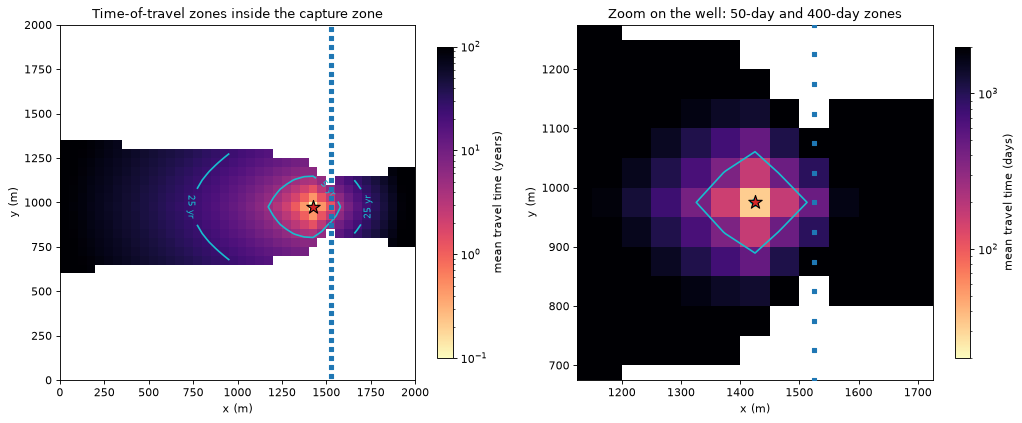

,cells (to the well),area km2 (to the well),cells (to the well cell)
50 d,1.0,0.002,1.0
400 d,7.0,0.018,8.0
5 yr,39.0,0.098,39.0
25 yr,182.0,0.455,182.0


In [6]:
t_zone = np.where(F >= CAPTURE_F, t_well, np.nan)  # times inside the capture zone only
t_exit = tt.mean_time_to_exit_cell[WELL]
levels = tuple(ZONE_TIMES.values())
labels = {limit: name for name, limit in ZONE_TIMES.items()}

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))
hbd.plot_cells(
    run.grb_file, step, t_zone / YEAR, ax=axes[0], cmap="magma_r", norm=LogNorm(0.1, 100.0),
    title="Time-of-travel zones inside the capture zone", label="mean travel time (years)",
    overlay=False,
)
hbd.add_contours(ax=axes[0], grb_file=run.grb_file, step=step, values=t_zone,
                 levels=levels[2:], colors="tab:cyan", fmt=labels)
x_w, y_w = spec.xy(spec.wells[0][1])
hbd.plot_cells(
    run.grb_file, step, t_zone, ax=axes[1], cmap="magma_r", norm=LogNorm(20.0, 2000.0),
    title="Zoom on the well: 50-day and 400-day zones", label="mean travel time (days)",
    overlay=False,
)
hbd.add_contours(ax=axes[1], grb_file=run.grb_file, step=step, values=t_zone,
                 levels=levels[:2], colors="tab:cyan", fmt=labels)
axes[1].set_xlim(x_w - 300.0, x_w + 300.0)
axes[1].set_ylim(y_w - 300.0, y_w + 300.0)
for ax in axes:
    hbd.overlay_features(ax, run.grb_file, step, packages=("RIV", "WEL"), legend=False)
fig.tight_layout()
plt.show()

rows = {}
for name, limit in ZONE_TIMES.items():
    rows[name] = {
        "cells (to the well)": helpers.zone_area(np.ones(step.n_cells), t_well, F, limit),
        "area km2 (to the well)": helpers.zone_area(step.area, t_well, F, limit) / 1e6,
        "cells (to the well cell)": helpers.zone_area(np.ones(step.n_cells), t_exit, F, limit),
    }
display(pd.DataFrame(rows).T.round(3))

How to read this:

- The **5-year and 25-year zones** are well resolved: tens to hundreds of cells, elongated upgradient and pulled towards the river, where the losing reaches deliver young water.
- The **50-day zone is the well cell alone** and the **400-day zone is a handful of cells**. At 50 m cells this grid cannot draw them: the residence time of the well cell alone (about 32 days at $n = 0.3$) is most of the 50-day budget. Whether a zone counts the time spent *in* the well cell (`mean_time`) or stops on entering it (`mean_time_to_exit_cell`) changes the answer by a whole cell. For short time limits, refine the grid around the well (tutorial 04 shows Voronoi grids) before reading off a zone.

## 5. The volume identity

Multiply each row of the travel-time equation by the cell's outflow $O_i$ (so that $\tau_i O_i = V_i$) and sum over all cells. The flows between cells cancel, as in the closure check of tutorial 01, and what remains is an exact identity (with $\mathrm{Src}_i$ the water entering the model in cell $i$ and $r_i$ MF6's budget residual):

$$
\sum_i \mathrm{Src}_i\, m_i \;-\; \sum_i r_i\, m_i \;=\; \sum_i V_i\, F_i .
$$

Dividing by the pumping rate $Q$ gives the **flux-weighted mean travel time of all the water reaching the well**:

$$
\bar t_Q \;=\; \frac{\sum_i \mathrm{Src}_i\, m_i}{\sum_i \mathrm{Src}_i\, F_i} \;=\; \frac{\sum_i V_i F_i}{Q}
\quad\text{(up to the residual terms)} .
$$

The right-hand side is a turnover time: the volume of water in the aquifer that will end up at the well, divided by the rate at which the well removes it. It needs no travel-time solve at all, only $F$ and the porosity.

In [7]:
check = travel_time_closure(step, res, tt, WELL)
print(f"sum Src m - sum r m:        {check.lhs - check.residual_term:16.1f} m3")
print(f"sum V F:                    {check.rhs:16.1f} m3  (water volume that ends at the well)")
print(f"relative error:             {check.relative_error:16.1e}")
print()
print(f"volume / pumping rate:      {tt.mean_transit_time[WELL]:10.1f} d = {tt.mean_transit_time[WELL] / YEAR:.1f} yr")
print(f"flux-weighted mean time:    {tt.flux_weighted_time[WELL]:10.1f} d")
assert check.relative_error < 1e-10

sum Src m - sum r m:              13433060.6 m3
sum V F:                          13433060.6 m3  (water volume that ends at the well)
relative error:                      0.0e+00

volume / pumping rate:         16791.3 d = 46.0 yr
flux-weighted mean time:       16791.3 d


The two numbers agree to the model's budget residual. The identity explains why the overall mean travel time is robust: it depends on the capture zone only through $\sum V F$, and the [dispersion study](../../docs/dispersion_study.md) found the flux-weighted mean travel time within 2 to 4 % of particle tracking and analytical solutions at this cell size.

The same means split by source package (sums over the cells where each package brings water in), at both end points:

In [8]:
means = helpers.eulerian_means(step, res, tt, WELL)
euler_table = pd.DataFrame(means).T.rename(index=SOURCE_LABELS)
euler_table["share of the well water"] = [
    1.0 if name == "all sources" else res.volume_from_by_term[WELL][name].sum() / res.destination_inflow[WELL]
    for name in means
]
display((euler_table.iloc[:, :2] / YEAR).round(1).join(euler_table.iloc[:, 2:].round(3)).rename(
    columns={"to the well": "to the well (yr)", "to the well cell": "to the well cell (yr)"}))

,to the well (yr),to the well cell (yr),share of the well water
all sources,46.0,45.9,1.000
river leakage,2.2,2.1,0.142
recharge,41.7,41.6,0.711
west edge (regional inflow),108.4,108.4,0.148


Recharge, 71 % of the well water, takes about 40 years on average. Regional inflow from the west edge is about a century old (it enters at the far end of the capture zone), and river water about two years: the losing reaches are next to the well. A flux-weighted mean over such different sources hides a wide distribution, which matters when a contaminant enters with one source only.

## 6. Comparison with MF6 PRT particles

Particle tracking gives an independent, purely advective answer on the same flow field. `gwsource.prt.track_particles` writes and runs an MF6 PRT model for one backward group:

- particles are released from every source term (recharge, river leakage, boundary inflow) in the cells with $F > 0$, spread over each cell's volume as MF6 spreads the source (in this one-layer model there is no vertical flow, so one release height suffices); each carries its share of the source flow as a **weight**, so averages over particles are flux-weighted;
- water counts as arriving when the particle *enters* the well cell, so the arrival time is compared with `mean_time_to_exit_cell`; where a well takes only part of its cell's outflow, the particle gives that share to the well and carries the rest on;
- particles passing a weak sink of another boundary (a gaining river cell) lose the share that this sink removes under full mixing, so that the captured flow stays consistent with the budget (`thin_weak_sinks=True`; see the module docstring of `gwsource.prt`).

PRT works on DIS and DISV grids only; on DISU the Eulerian time is the only option. `subdivisions=2` gives 16 particles per source term in a DIS cell.

In [9]:
start = time.perf_counter()
prt = track_particles(
    run.ws, step, res, WELL, PrtConfig(porosity=POROSITY, subdivisions=PRT_SUBDIVISIONS),
    MF6, WORK / "prt",
)
elapsed = time.perf_counter() - start
print(f"{prt.release.n} particles from {np.isfinite(prt.cell_capture_fraction).sum()} cells, "
      f"PRT run and evaluation in {elapsed:.1f} s")
print(f"captured particle flow: {prt.captured_flow:.1f} m3/d of {res.destination_inflow[WELL]:.1f} m3/d")

18208 particles from 1133 cells, PRT run and evaluation in 9.5 s
captured particle flow: 799.9 m3/d of 800.0 m3/d


The particles that reach the well carry 800 m³/d, as they should: the release points are a quadrature of the uniform areal sources, so the particle count adds an error well below 1 %.

### Overall means

In [10]:
compare = pd.DataFrame({
    "PRT particles": {name: prt.package_mean_arrival.get(name, np.nan) for name in means if name != "all sources"},
    "Eulerian, to the well cell": {name: m["to the well cell"] for name, m in means.items() if name != "all sources"},
})
compare.loc["all sources"] = [prt.mean_arrival, means["all sources"]["to the well cell"]]
compare["difference"] = compare["PRT particles"] / compare["Eulerian, to the well cell"] - 1.0
compare = compare.rename(index=SOURCE_LABELS)
display((compare.iloc[:, :2] / YEAR).round(1).join(compare["difference"].map("{:+.1%}".format)).rename(
    columns={"PRT particles": "PRT (yr)", "Eulerian, to the well cell": "Eulerian (yr)"}))

,PRT (yr),Eulerian (yr),difference
river leakage,1.7,2.1,-20.1%
recharge,40.8,41.6,-2.1%
west edge (regional inflow),110.7,108.4,+2.1%
all sources,45.7,45.9,-0.5%


Over all the water reaching the well, the flux-weighted particle arrival and the Eulerian mean agree to a fraction of a per cent. This is the volume identity at work: for particles too, the flux-weighted mean arrival is the volume of water in the captured stream tubes divided by the pumping rate, and the two methods differ only in where they draw the edge of the capture zone, which full mixing smears over a few cells. The test suite holds the difference within $h/L$, the cell size over the size of the capture zone (about 5 % here).

By source the agreement is looser. River water travels a short distance through few cells, so the few cells of numerical mixing between the river and the well weigh more; regional inflow comes in through the constant-head cells, whose water the particle helper releases at the water table, an approximation of where it really enters.

### Cell by cell

Each release cell has a flux-weighted mean particle arrival (`prt.cell_mean_arrival`) and a captured fraction (`prt.cell_capture_fraction`, the particle analogue of $F$ for the water entering in that cell).

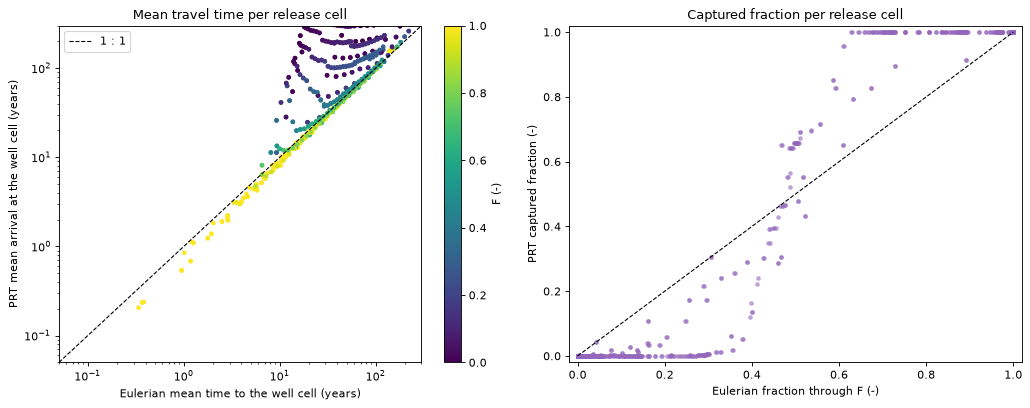

PRT / Eulerian time,  456 core, F >= 0.5 cells: median 0.96, 5-95 % range 0.78 to 1.06
PRT / Eulerian time,  676 edge, F < 0.5 cells: median 5.72, 5-95 % range 1.09 to 29.15
mean |PRT captured fraction - F|: 0.058 over all release cells, 0.164 over the 372 edge cells (0.05 < F < 0.95)


In [11]:
euler_cell = tt.mean_time_to_exit_cell[WELL]
both = np.isfinite(prt.cell_mean_arrival) & np.isfinite(euler_cell) & (euler_cell > 0)
released = np.isfinite(prt.cell_capture_fraction)
log_ratio = np.log10(prt.cell_mean_arrival[both] / euler_cell[both])

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))
points = axes[0].scatter(
    euler_cell[both] / YEAR, prt.cell_mean_arrival[both] / YEAR, c=F[both], s=10,
    cmap="viridis", vmin=0.0, vmax=1.0,
)
lims = (0.05, 300.0)
axes[0].plot(lims, lims, "k--", lw=1, label="1 : 1")
axes[0].set(xscale="log", yscale="log", xlim=lims, ylim=lims,
            xlabel="Eulerian mean time to the well cell (years)",
            ylabel="PRT mean arrival at the well cell (years)",
            title="Mean travel time per release cell")
axes[0].legend(loc="upper left")
plt.colorbar(points, ax=axes[0], label="F (-)")

axes[1].scatter(F[released], prt.cell_capture_fraction[released], s=10, color="tab:purple", alpha=0.5)
axes[1].plot((0, 1), (0, 1), "k--", lw=1)
axes[1].set(xlabel="Eulerian fraction through F (-)", ylabel="PRT captured fraction (-)",
            title="Captured fraction per release cell", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
fig.tight_layout()
plt.show()

edge = released & (F > 0.05) & (F < 0.95)
for name, cells in (("core, F >= 0.5", F[both] >= CAPTURE_F), ("edge, F < 0.5", F[both] < CAPTURE_F)):
    r = 10 ** log_ratio[cells]
    print(f"PRT / Eulerian time, {cells.sum():4d} {name} cells: median {np.median(r):.2f}, "
          f"5-95 % range {np.percentile(r, 5):.2f} to {np.percentile(r, 95):.2f}")
print(f"mean |PRT captured fraction - F|: {np.abs(prt.cell_capture_fraction[released] - F[released]).mean():.3f} "
      f"over all release cells, {np.abs(prt.cell_capture_fraction[edge] - F[edge]).mean():.3f} "
      f"over the {edge.sum()} edge cells (0.05 < F < 0.95)")

Two populations show up:

- **The core of the capture zone** (yellow, $F$ near 1) lies close to the 1 : 1 line; the particles arrive a few per cent sooner than the Eulerian mean.
- **The edge** (dark points, small $F$) departs strongly: the few particles from an edge cell that do reach the well were released next to the dividing streamline and travel slowly around the edge of the zone, so their arrival is much later than the Eulerian mean of the same cell.

The captured fractions (right) show the same edge from the other side: particles say 0 or 1 for most of a cell's water, full mixing a smooth value in between. Both methods are right about what they compute; they compute different things.

### Why full mixing and advection differ cell by cell

- **A particle follows one path; mixed water follows all of them.** A particle released at a point follows one streamline and arrives once: its time is a single advective arrival. Under full mixing, the water leaving a cell is split among all its outflow faces in proportion to the flows, and again at every cell downstream. The Eulerian $\bar t_i$ is the *mean of that whole mixed distribution* of routes and times. Some of the mixed water drifts onto slower streamlines further from the well, some onto faster ones; the mean need not match the particle from the same cell.
- **The mean is not the first arrival.** Because the mixed water spreads, part of it arrives earlier than the mean and part much later. The Eulerian mean is not the earliest arrival of a contaminant, and the mixing-induced early tail is a grid artefact (numerical dispersion), not physical dispersion.
- **Near the edge of the capture zone, mixing moves water across it** in both directions, which is what makes $F$ fractional there. The time of the small captured share of an edge cell is the time of water that has drifted inwards, which a particle from that cell would not do.
- **Within a cell** a particle starts at a point; the Eulerian time starts from the cell as a whole.

None of this affects the totals: spreading moves water between streamlines in both directions, and the volume identity ties both methods' overall means to $\sum V F / Q$. The size of the spreading against grid resolution, and the thresholds that compensate for it, are quantified in [`docs/dispersion_study.md`](../../docs/dispersion_study.md); there, the flux-weighted mean travel time stayed within 2 to 4 % of particles and analytical solutions at cell sizes of 50 m or less, while the zone edge band narrowed only as $h^{0.5}$.

## 7. Time-of-travel zones in practice

Compare the 5-year and 25-year zones from each method: a cell is in the particle zone when at least half its released water is captured and its mean particle arrival is within the limit, the same rule as for the Eulerian zone.

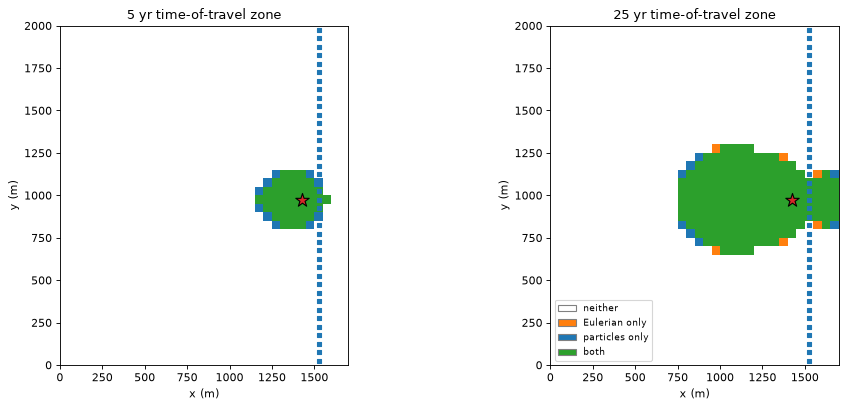

,Eulerian (km2),particles (km2),both (km2)
5 yr,0.098,0.122,0.098
25 yr,0.455,0.465,0.440


In [12]:
prt_t = prt.cell_mean_arrival
prt_f = np.nan_to_num(prt.cell_capture_fraction)
zone_colours = ListedColormap(["white", "tab:orange", "tab:blue", "tab:green"])
names = ("neither", "Eulerian only", "particles only", "both")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.2))
rows = {}
for ax, name in zip(axes, ("5 yr", "25 yr")):
    limit = ZONE_TIMES[name]
    in_euler = (F >= CAPTURE_F) & (t_well <= limit)
    in_prt = (prt_f >= CAPTURE_F) & np.isfinite(prt_t) & (prt_t <= limit)
    category = in_euler.astype(int) + 2 * in_prt.astype(int)
    hbd.plot_cells(
        run.grb_file, step, category.astype(float), ax=ax, cmap=zone_colours, vmin=-0.5, vmax=3.5,
        title=f"{name} time-of-travel zone", overlay=False, colorbar=False,
    )
    hbd.overlay_features(ax, run.grb_file, step, packages=("RIV", "WEL"), legend=False)
    ax.set_xlim(0.0, 1700.0)
    rows[name] = {
        "Eulerian (km2)": step.area[in_euler].sum() / 1e6,
        "particles (km2)": step.area[in_prt].sum() / 1e6,
        "both (km2)": step.area[in_euler & in_prt].sum() / 1e6,
    }
axes[1].legend(handles=[Patch(facecolor=zone_colours(i), edgecolor="0.5", label=n) for i, n in enumerate(names)],
               loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).T.round(3))

The zones overlap over most of their area and differ by a ring of cells along the edge. The particle zone is a little larger at 5 years (in the core the particles arrive a few per cent sooner, which near the well moves a ring of cells across the limit); at 25 years the two areas agree within a few per cent.

Practical guidance:

- **Use particles to draw the edge of a time-of-travel zone.** A regulatory boundary is an advective line; particles draw it without numerical mixing. Refine the grid near the well when the time limit is short (50 days, 400 days): the zone must span many cells to be meaningful.
- **Use the Eulerian time for full coverage.** It gives every cell a value, including cells that few or no particles visit and weak-sink cells such as the river, it is consistent with the fractions and volumes of the same trace (shares and times add up exactly), it costs one extra right-hand side on an already factorised matrix, and it works where particles do not: DISU grids, package networks and models split into several models (tutorial 07), and every realisation of a parameter ensemble (tutorial 09).
- **Use the mean for what it is.** The Eulerian time, like the flux-weighted particle time, is a mean. Early arrivals matter for pathogen zones; neither mean describes them, and full mixing adds spurious early (and late) arrivals of its own.
- **Report the porosity.** Every time here is proportional to it, and it is rarely known to better than a factor of 1.5.

## 8. Sanity checks

The exit-cell identity (the same derivation, stopping on entry to the well cell), the particle flow, and the overall agreement within $h/L$:

In [13]:
exit_check = exit_cell_closure(step, res, tt, WELL)
print(f"exit-cell identity, relative error: {exit_check.relative_error:.1e}")
assert exit_check.relative_error < 1e-10

assert abs(prt.captured_flow / res.destination_inflow[WELL] - 1.0) < 0.01
h_over_l = spec.delr / np.sqrt(F @ step.area)
difference = prt.mean_arrival / means["all sources"]["to the well cell"] - 1.0
print(f"PRT vs Eulerian overall: {difference:+.2%} (tolerance h / L = {h_over_l:.1%})")
assert abs(difference) < h_over_l

exit-cell identity, relative error: 0.0e+00
PRT vs Eulerian overall: -0.50% (tolerance h / L = 4.6%)


## Key points

- Travel times need a **porosity**; `gwsource` has no default. In a steady model every time is exactly proportional to it.
- The **Eulerian mean travel time** comes from one more right-hand side on the backward matrix. It is the mean time of the water that does reach the destination, from entering a cell until leaving through the destination (`mean_time`) or until entering the destination's cell (`mean_time_to_exit_cell`, comparable with particles).
- The **volume identity** is exact: the flux-weighted mean travel time to the well equals $\sum V F / Q$, the water volume that ends at the well divided by the pumping rate. It makes the overall mean robust to the mixing assumption.
- **MF6 PRT** particles, flux-weighted through `gwsource.prt.track_particles`, agree with the Eulerian overall mean to a fraction of a per cent here, and differ cell by cell: a particle gives one advective arrival, full mixing the mean of a spread distribution. See [`docs/dispersion_study.md`](../../docs/dispersion_study.md).
- For **time-of-travel zones**, draw the edge with particles (and a grid fine enough for the time limit); use the Eulerian times for full coverage, unstructured grids, networks and ensembles.

## Next

[07 · Networks and multi-model](../07_networks_multimodel/07_networks_multimodel.ipynb): water that moves through streams, drains and multi-aquifer wells, and models split into several models.